_ExplainDB — Copyright (C) 2026 Prof. Dr. Jens Dittrich, Saarland University._  
_Licensed under the GNU Affero General Public License v3 (AGPL-3.0). See the `LICENSE` file._

# B⁺-trees

This notebook accompanies lecture 06a. It uses the B⁺-tree of ExplainDB,
[`system/indexes/btree.py`](../system/indexes/btree.py), in two ways:

1. It builds the example tree of the lecture by hand, inserts four keys into it and shows the tree after each insert.
   Two of the inserts split a leaf, the last one splits an inner node as well. Then it runs a point query and a range
   query on the tree.
2. It shows that the inner nodes of a B⁺-tree are a model of the data: inserted into a tree whose leaves only count,
   all data falls into partitions of almost equal size.

The tutorial page [B⁺-Tree](<../docs/tutorial/02 Indexing/B+-Tree.md>) explains the structure and the interface.

In [1]:
import sys, pathlib

# Put the repo root (the directory containing `system/`) on sys.path so
# `from system...` works whether this notebook is opened from its own
# folder or from the repo root.
for _p in (pathlib.Path.cwd(), *pathlib.Path.cwd().parents):
    if (_p / "system").is_dir():
        if str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
        break

## The example tree of the lecture

The next cell builds the tree of lecture 06a (slides 16 to 22) by hand: six leaves with up to four entries each and
three inner nodes with up to three keys each (`Leaf(4, ...)` and `Inner(3, ...)`, in a tree
`BPlusTree[int, int](3, 4)` with the same capacities). Each leaf maps keys (the green row) to
values (the grey row) and is linked to its left and right neighbour. Then the cell inserts the keys 50, 53, 55 and 58
with `put` and shows the tree after each insert.

Initial B-tree:


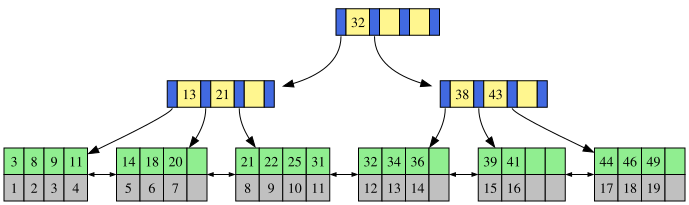

After inserting 50:


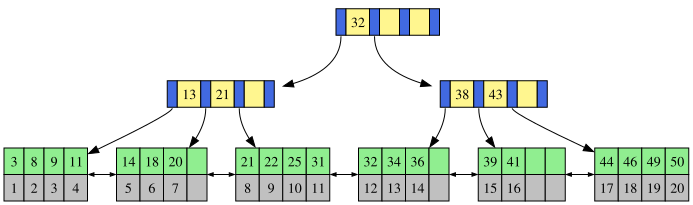

After inserting 53:


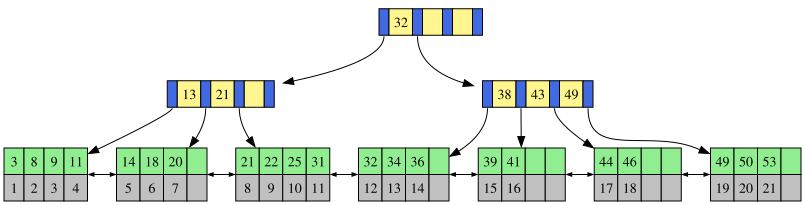

After inserting 55:


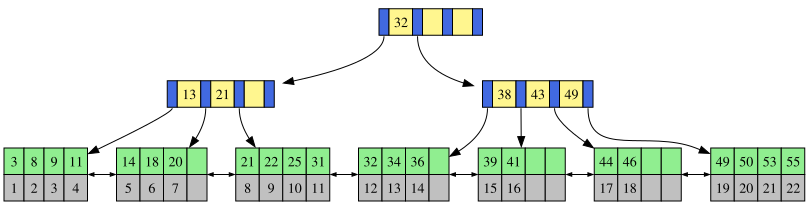

After inserting 58:


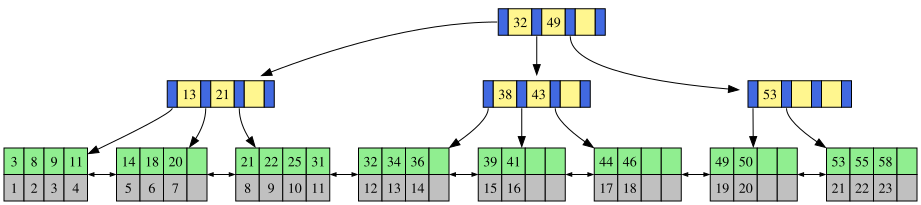

In [2]:
from system.indexes.btree import BPlusTree

# create leaves
leaf_1 = BPlusTree.Leaf(4, [3, 8, 9, 11], [1, 2, 3, 4])
leaf_2 = BPlusTree.Leaf(4, [14, 18, 20], [5, 6, 7])
leaf_3 = BPlusTree.Leaf(4, [21, 22, 25, 31], [8, 9, 10, 11])
leaf_4 = BPlusTree.Leaf(4, [32, 34, 36], [12, 13, 14])
leaf_5 = BPlusTree.Leaf(4, [39, 41], [15, 16])
leaf_6 = BPlusTree.Leaf(4, [44, 46, 49], [17, 18, 19])

# connect leaves
leaf_1.next = leaf_2
leaf_2.previous = leaf_1
leaf_2.next = leaf_3
leaf_3.previous = leaf_2
leaf_3.next = leaf_4
leaf_4.previous = leaf_3
leaf_4.next = leaf_5
leaf_5.previous = leaf_4
leaf_5.next = leaf_6
leaf_6.previous = leaf_5

# create inner nodes
inner_1 = BPlusTree.Inner(3, [13, 21], [leaf_1, leaf_2, leaf_3])
inner_2 = BPlusTree.Inner(3, [38, 43], [leaf_4, leaf_5, leaf_6])

# create root node
root = BPlusTree.Inner(3, [32], [inner_1, inner_2])

# create B-tree
bplustree = BPlusTree[int, int](3, 4)
bplustree.root = root
print("Initial B-tree:")
bplustree.show()

# insert values
bplustree.put(50, 20)
print("After inserting 50:")
bplustree.show()
bplustree.put(53, 21)
print("After inserting 53:")
bplustree.show()
bplustree.put(55, 22)
print("After inserting 55:")
bplustree.show()
bplustree.put(58, 23)
print("After inserting 58:")
bplustree.show()

What the four inserts do:

- **50** goes into the rightmost leaf, which still has room.
- **53** also belongs in that leaf, which is now full. The leaf splits into `[44 46]` and `[49 50 53]`, and the first
  key of the new right leaf, 49, is copied up into its parent: `[38 43 49]`.
- **55** goes into the leaf `[49 50 53]`, which has room.
- **58** belongs in that leaf, which is full again: it splits into `[49 50]` and `[53 55 58]`, and 53 has to go up.
  The parent first takes 53 and so holds four keys, `[38 43 49 53]`, one more than fits. It splits into `[38 43]` and
  `[53]`, and the key between them, 49, moves up into the root: `[32 49]`. Unlike a leaf split, an inner node split
  moves this key up instead of copying it.

The tree has the same height after all four inserts: it only grows when the root splits.

## Point and range queries

A point query (`get`) follows one path from the root to a leaf: in each inner node it takes the pointer whose interval
holds the key. A range query (`get_all_in_range`, both bounds included) finds the first key like a point query and
then walks along the linked leaves until a key is too big. The query below for the keys 20 to 40 starts in the second
leaf, reads four leaves and stops at 41, the first key greater than 40, in the fifth leaf. On the way it crosses
from the subtree left of the root key 32 into the subtree between 32 and 49.

In [3]:
# point query: the value for key 41
print("get(41):", list(bplustree.get(41)))

# a key that is not in the tree: get raises a KeyError when its result is read
try:
    list(bplustree.get(40))
except KeyError:
    print("get(40): key 40 is not in the tree")

# range query: the values for all keys from 20 to 40, both bounds included
print("get_all_in_range(20, 40):", list(bplustree.get_all_in_range(20, 40)))

get(41): [16]
get(40): key 40 is not in the tree
get_all_in_range(20, 40): [7, 8, 9, 10, 11, 12, 13, 14, 15]


## Using a B⁺-tree for partitioning

The inner nodes of a B⁺-tree are a model of the underlying data: their keys split the data into intervals. As every leaf
is between half full and full, the intervals hold the same number of entries up to a factor of about two; with the
sample used here they come out almost equal. Let's see why. The data are the latitudes of a set of locations.

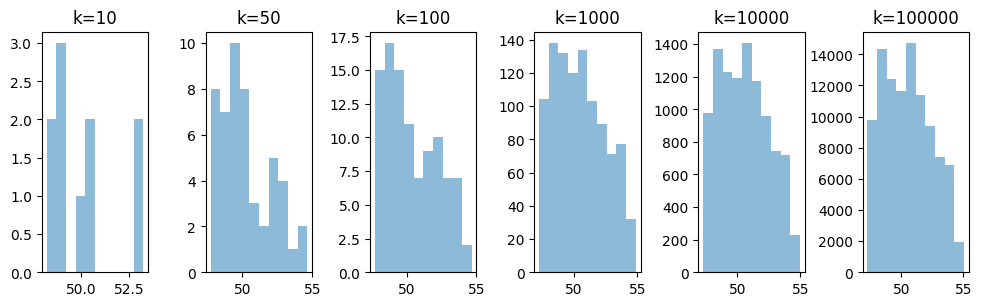

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import random as rnd

# Load latitude/longitude data from disk
loaded_data = np.fromfile("latitude_longitude.bin", dtype=np.float32).reshape(-1, 2)

# remove duplicates as our b-tree cannot handle duplicates so far:
# correct would be to keep duplicates for counting, but this is not necessary to prove the point here
data = set()
for latitude, longitude in loaded_data:
    data.add(latitude)

# We need a sample of the data, i.e. a subset that has similar statistical properties:
# (1.) let's shuffle the input, always in the same way, so that every run shows the same pictures:
data = list(data)
rnd.seed(42)
rnd.shuffle(data)

# (2.) And show histograms of varying granularity
fig, axs = plt.subplots(1, 6, figsize=(10, 3))
fig.tight_layout()

for idx, k in enumerate([10, 50, 100, 1000, 10000, 100000]):
    # take the first k elements as a sample:
    sample = data[:k]

    # plot the histogram:
    axs[idx].title.set_text(f"k={k}")
    axs[idx].hist(sample, bins=10, alpha=0.5)
    axs[idx].plot()

The bigger the sample, the less the shape of the histogram changes: a sample of 10,000 latitudes already has about
the same shape as the sample of 100,000.

Now we use a B⁺-tree to create an equi-depth partitioning, i.e. one whose partitions all hold about the same number
of entries:

In [5]:
# create a b-tree with a decent sample size:
# we use small inners and big leaves, the goal here is to obtain a small "inner tree" (all nodes except the leaves)
bplustree = BPlusTree[np.float32, np.float32](5, 2000)
sample = data[:10000]

# insert the sample data
for el in sample:
    bplustree.put(el, el)

In [6]:
# this can be slow:
# bplustree.show()

In [7]:
# now we replace the leaf level by CountingLeaves
# those are leaves that do not store the data but simply count the number of put calls
bplustree.convert_to_counting_leaf_tree()

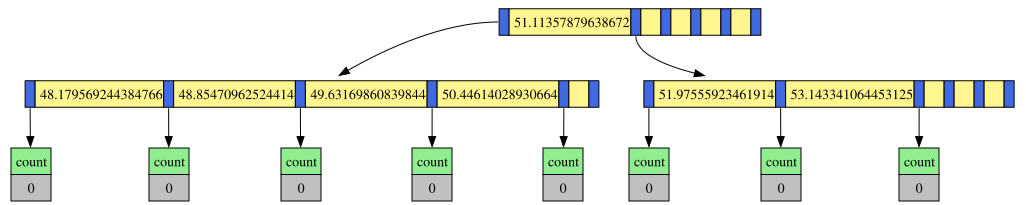

In [8]:
bplustree.show()

All leaves were replaced: the counts are all set to 0.

In [9]:
# Now, let's insert all data into this counting tree:
for el in data:
    bplustree.put(el, el)

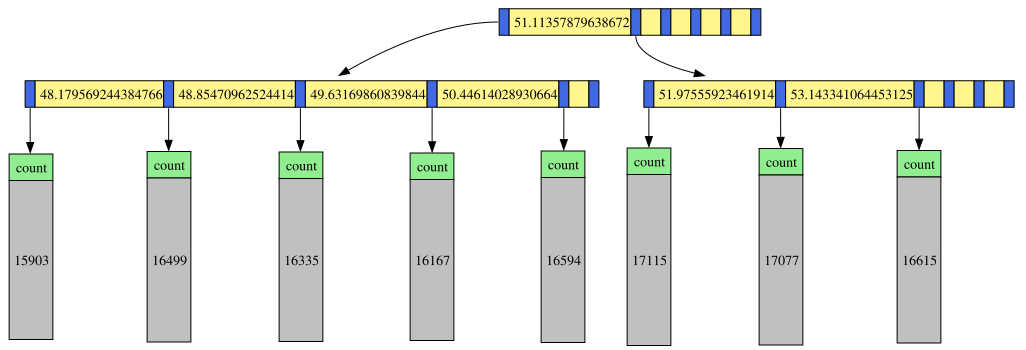

In [10]:
# Here is the result
bplustree.show()

We created an equi-depth partitioning: each counting leaf counts about the same number of latitudes. The keys of
the inner nodes, which the tree learned from the sample alone, split all the data into partitions of almost equal
size. Where the data is dense, the intervals are narrow; where it is sparse, they are wide.